In [ ]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

RANDOM_STATE = 42


In [ ]:
DATA_PATH = r"C:\Users\ayomi\Downloads\TSLA (1).csv"

df = pd.read_csv(DATA_PATH)

print("Tesla dataset loaded successfully.")
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
df.head()



Loaded: TSLA (1).csv
Rows: 1,258 | Columns: 7


,Date,Open,High,Low,Close,Adj Close,Volume
0,8/16/2016,45.098000,45.438000,44.681999,44.722000,44.722000,11335500
1,8/17/2016,44.866001,44.966000,44.560001,44.647999,44.647999,8935500
2,8/18/2016,44.764000,45.132000,44.458000,44.702000,44.702000,8572500
3,8/19/2016,44.708000,45.034000,44.506001,45.000000,45.000000,8297500
4,8/22/2016,44.834000,45.021999,44.535999,44.585999,44.585999,10327500


In [3]:
df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates(subset="date").reset_index(drop=True)

quality_summary = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "data_type": df.dtypes.astype(str)
})

print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Duplicate dates:", df["date"].duplicated().sum())
quality_summary


Date range: 2016-08-16 to 2021-08-13
Duplicate dates: 0


,missing_values,data_type
date,0,datetime64[ns]
open,0,float64
high,0,float64
low,0,float64
close,0,float64
adj_close,0,float64
volume,0,int64


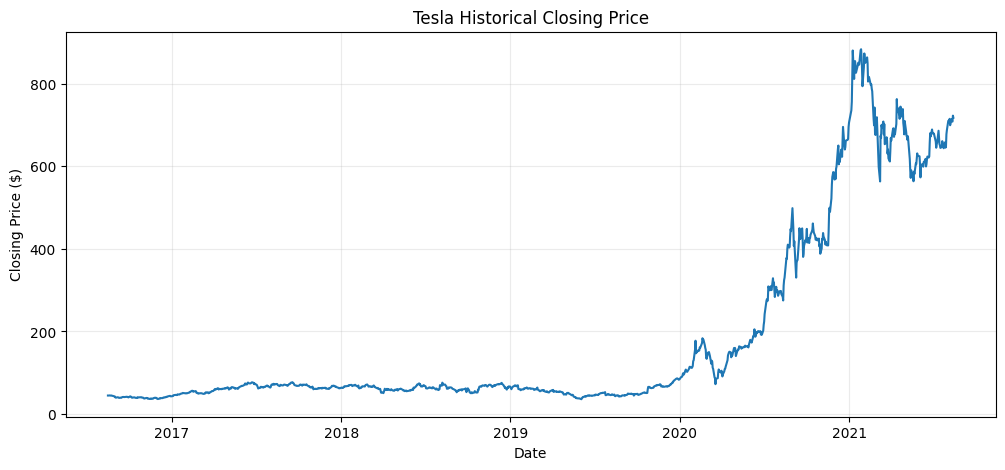

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df["date"], df["close"])
ax.set_title("Tesla Historical Closing Price")
ax.set_xlabel("Date")
ax.set_ylabel("Closing Price ($)")
ax.grid(alpha=0.25)
plt.show()


In [5]:
model_df = df.copy()

# Current-day information available before predicting the following trading day.
model_df["return_1d"] = model_df["close"].pct_change()
model_df["log_return_1d"] = np.log(model_df["close"] / model_df["close"].shift(1))
model_df["range_pct"] = (model_df["high"] - model_df["low"]) / model_df["close"]
model_df["open_close_pct"] = (model_df["close"] - model_df["open"]) / model_df["open"]
model_df["volume_change"] = model_df["volume"].pct_change()
model_df["volume_change"] = model_df["volume_change"].replace([np.inf, -np.inf], np.nan)

# Lagged return and price-momentum features.
for lag in [1, 2, 3, 5, 10, 15]:
    model_df[f"return_lag_{lag}"] = model_df["return_1d"].shift(lag - 1)
    model_df[f"close_ratio_lag_{lag}"] = model_df["close"] / model_df["close"].shift(lag) - 1

# Rolling trend, volatility and volume features.
for window in [3, 5, 10, 15, 20]:
    model_df[f"return_mean_{window}"] = model_df["return_1d"].rolling(window).mean()
    model_df[f"return_std_{window}"] = model_df["return_1d"].rolling(window).std()
    model_df[f"volume_ratio_{window}"] = model_df["volume"] / model_df["volume"].rolling(window).mean()
    model_df[f"close_ma_ratio_{window}"] = model_df["close"] / model_df["close"].rolling(window).mean() - 1

# One-day-ahead targets.
model_df["target_return"] = model_df["close"].shift(-1) / model_df["close"] - 1
model_df["target_close"] = model_df["close"].shift(-1)

feature_cols = [
    c for c in model_df.columns
    if (
        c in ["return_1d", "log_return_1d", "range_pct", "open_close_pct", "volume_change"]
        or c.startswith("return_lag_")
        or c.startswith("close_ratio_lag_")
        or c.startswith("return_mean_")
        or c.startswith("return_std_")
        or c.startswith("volume_ratio_")
        or c.startswith("close_ma_ratio_")
    )
]

model_df = model_df.dropna(
    subset=feature_cols + ["target_return", "target_close"]
).reset_index(drop=True)

print("Modelling rows:", len(model_df))
print("Number of features:", len(feature_cols))
print("Target: next-day percentage return")


Modelling rows: 1237
Number of features: 37
Target: next-day percentage return


In [6]:
split_idx = int(len(model_df) * 0.70)

train_df = model_df.iloc[:split_idx].copy()
test_df = model_df.iloc[split_idx:].copy()

X_train = train_df[feature_cols]
y_train = train_df["target_return"]

X_test = test_df[feature_cols]
y_test = test_df["target_return"]

print("Training period:", train_df["date"].min().date(), "to", train_df["date"].max().date())
print("Test period:", test_df["date"].min().date(), "to", test_df["date"].max().date())
print("Training rows:", len(train_df))
print("Test rows:", len(test_df))


Training period: 2016-09-14 to 2020-02-21
Test period: 2020-02-24 to 2021-08-12
Training rows: 865
Test rows: 372


In [7]:
actual_close = test_df["target_close"].to_numpy()
naive_pred_close = test_df["close"].to_numpy()

naive_mae = mean_absolute_error(actual_close, naive_pred_close)
naive_rmse = np.sqrt(mean_squared_error(actual_close, naive_pred_close))

print(f"Naive baseline MAE:  ${naive_mae:,.2f}")
print(f"Naive baseline RMSE: ${naive_rmse:,.2f}")


Naive baseline MAE:  $14.23
Naive baseline RMSE: $20.39


In [8]:
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [1, 2],
    "learning_rate": [0.01, 0.03, 0.05],
    "subsample": [0.8],
    "colsample_bytree": [0.8]
}

tscv = TimeSeriesSplit(n_splits=5)

grid_search = GridSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=1
    ),
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print(f"Best CV return MAE: {-grid_search.best_score_:.5f}")


Best parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 1, 'n_estimators': 50, 'subsample': 0.8}
Best CV return MAE: 0.02308


In [9]:
pred_return = best_model.predict(X_test)
pred_close = test_df["close"].to_numpy() * (1 + pred_return)

xgb_mae = mean_absolute_error(actual_close, pred_close)
xgb_rmse = np.sqrt(mean_squared_error(actual_close, pred_close))
xgb_r2 = r2_score(actual_close, pred_close)

direction_accuracy = np.mean(
    np.sign(pred_return) == np.sign(y_test.to_numpy())
)

print(f"XGBoost MAE:               ${xgb_mae:,.2f}")
print(f"XGBoost RMSE:              ${xgb_rmse:,.2f}")
print(f"XGBoost R²:                 {xgb_r2:.4f}")
print(f"Direction accuracy:         {direction_accuracy:.1%}")


XGBoost MAE:               $14.23
XGBoost RMSE:              $20.39
XGBoost R²:                 0.9923
Direction accuracy:         53.5%


In [10]:
comparison = pd.DataFrame({
    "Model": ["Naive: Previous Close", "XGBoost"],
    "MAE ($)": [naive_mae, xgb_mae],
    "RMSE ($)": [naive_rmse, xgb_rmse]
}).set_index("Model")

comparison.round(4)


,MAE ($),RMSE ($)
Model,,
Naive: Previous Close,14.2268,20.387
XGBoost,14.2257,20.395


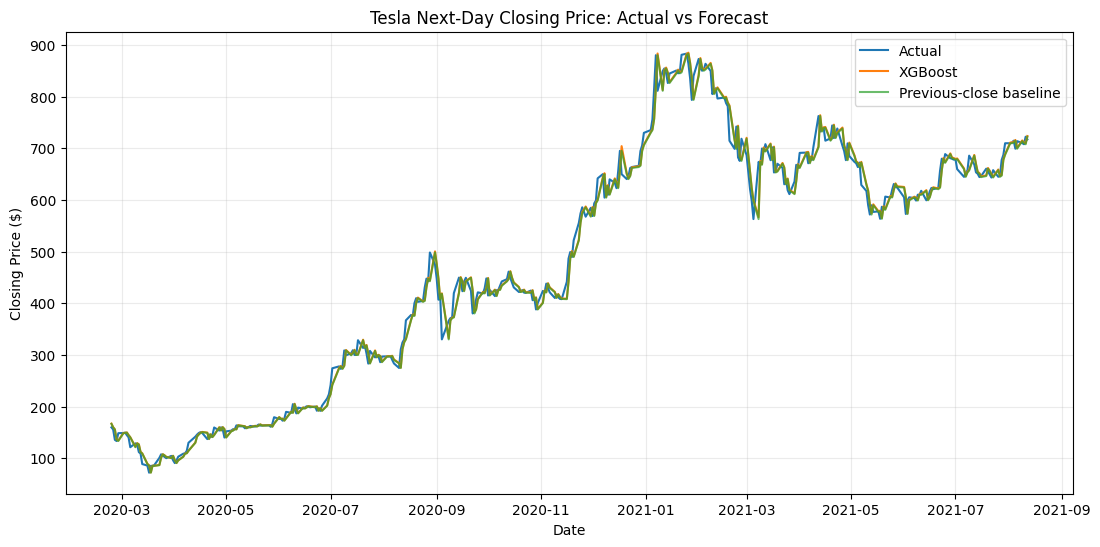

In [11]:
results = pd.DataFrame({
    "date": test_df["date"],
    "actual_close": actual_close,
    "xgboost_predicted_close": pred_close,
    "naive_predicted_close": naive_pred_close
})

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(results["date"], results["actual_close"], label="Actual")
ax.plot(results["date"], results["xgboost_predicted_close"], label="XGBoost")
ax.plot(results["date"], results["naive_predicted_close"], label="Previous-close baseline", alpha=0.7)
ax.set_title("Tesla Next-Day Closing Price: Actual vs Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Closing Price ($)")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


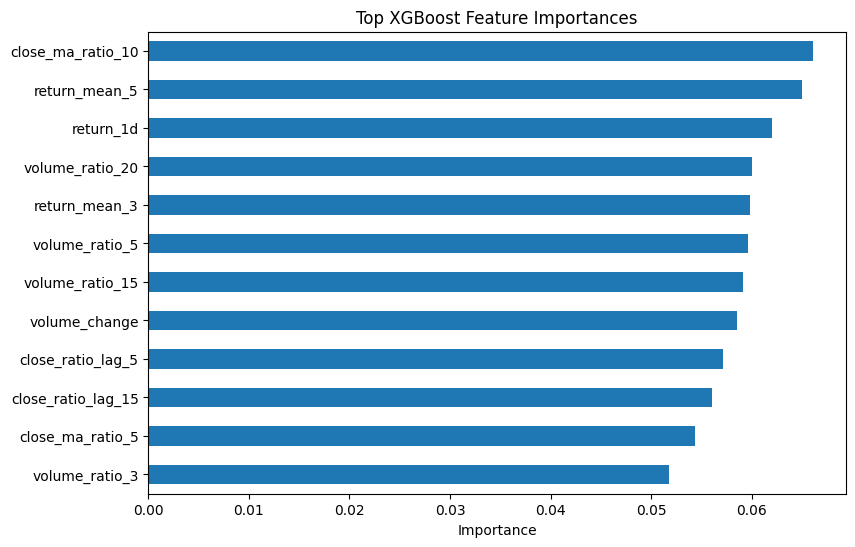

,importance
close_ma_ratio_10,0.066058
return_mean_5,0.064977
return_1d,0.062018
volume_ratio_20,0.059989
return_mean_3,0.059830
volume_ratio_5,0.059629
volume_ratio_15,0.059132
volume_change,0.058535
close_ratio_lag_5,0.057135
close_ratio_lag_15,0.056057


In [12]:
feature_importance = (
    pd.Series(best_model.feature_importances_, index=feature_cols)
    .sort_values(ascending=False)
    .head(12)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 6))
feature_importance.plot(kind="barh", ax=ax)
ax.set_title("Top XGBoost Feature Importances")
ax.set_xlabel("Importance")
plt.show()

feature_importance.sort_values(ascending=False).to_frame("importance")


In [13]:
results["absolute_error"] = (
    results["actual_close"] - results["xgboost_predicted_close"]
).abs()

results.tail(10).round(2)


,date,actual_close,xgboost_predicted_close,naive_predicted_close,absolute_error
1227,2021-07-30,709.67,688.55,687.20,21.12
1228,2021-08-02,709.74,711.07,709.67,1.33
1229,2021-08-03,710.92,711.14,709.74,0.22
1230,2021-08-04,714.63,712.32,710.92,2.31
1231,2021-08-05,699.10,716.04,714.63,16.94
1232,2021-08-06,713.76,700.48,699.10,13.28
1233,2021-08-09,709.99,715.17,713.76,5.18
1234,2021-08-10,707.82,711.39,709.99,3.57
1235,2021-08-11,722.25,709.21,707.82,13.04
1236,2021-08-12,717.17,723.67,722.25,6.50
